In [35]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

결혼식장에서 참석인원이 식사를 하고 사는 사람을 파악해서 음식을 준비하려고 합니다
1. 참석인원(total), 식사인원(reception)을 학습하여 참석 300명일때 식사인원을 예측하시오
2. 산점도그래프와 직선그래프를 출력하시오

In [44]:
df= pd.read_csv('data/QuizData.csv')
df.head()

,total,reception
0,118,62
1,253,148
2,320,201
3,94,80
4,155,92


In [50]:
df.iloc[:,:-1].values

array([[118],
       [253],
       [320],
       [ 94],
       [155],
       [188],
       [201],
       [338],
       [186],
       [183],
       [223],
       [392],
       [ 86],
       [112],
       [129],
       [223],
       [288],
       [262],
       [143],
       [179]])

In [ ]:
# 데이터 전처리 : 2차원으로 만들기
# 행 전체중 뒤에서 1개 제외한 나머지가 data
data=df.iloc[:,:-1].values
label=df.iloc[:,-1:].values

In [ ]:
# 학습, 테스트용 데이터 분리
train_data, test_data, train_label, test_label= train_test_split(data,label)

In [ ]:
# 데이터 학습
lr=LinearRegression()
lr.fit(train_data, train_label)

# 예측
result= lr.predict(test_data)
print("예측인원:",result)

# 정확도
score=lr.score(test_data, test_label)
print("정확도:",score)

# 기울기
print('기울기:', lr.coef_)
print('y절편:',lr.intercept_)

예측인원: [[158.73293659]
 [ 61.19826788]
 [239.91448719]
 [163.98929598]
 [208.37633084]]
정확도: 0.8017137937531771
기울기: [[0.58403993]]
y절편: [10.97083369]


식사인원: [[186.18281341]]


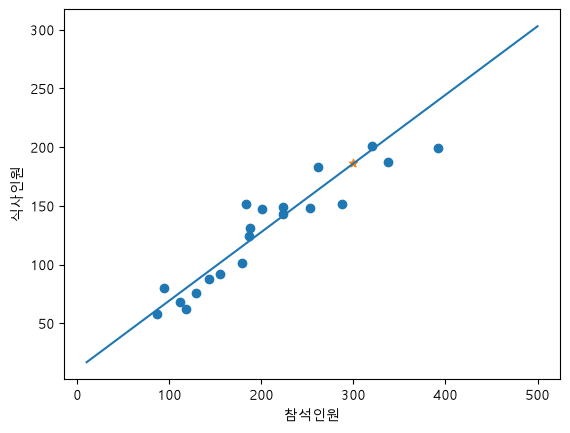

In [46]:
in_data= input('참석인원')
in_data=float(in_data)
predict=lr.predict([[in_data]])
print('식사인원:',predict)

plt.scatter(data, label)
plt.scatter(in_data, predict,marker='*')
plt.plot([10,500],[10*lr.coef_[0]+lr.intercept_,500*lr.coef_[0]+lr.intercept_])

plt.xlabel('참석인원')
plt.ylabel('식사인원')
plt.show()